In [59]:
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/colab_dataset/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
import pandas as pd, re

def norm(s):
    s = str(s).strip().lower()
    s = re.sub(r'[^a-z0-9 ]', '', s)
    return re.sub(r'\s+', ' ', s).strip()

In [61]:
census = pd.read_csv(path+'india-districts-census-2011.csv')
census['district_key'] = census['District name'].apply(norm)
census['state_key'] = census['State name'].apply(norm)
census['dkey'] = census['state_key'] + '__' + census['district_key']
census.head()

,District code,State name,District name,Population,Male,Female,Literate,Male_Literate,Female_Literate,SC,...,Power_Parity_Rs_240000_330000,Power_Parity_Rs_150000_330000,Power_Parity_Rs_330000_425000,Power_Parity_Rs_425000_545000,Power_Parity_Rs_330000_545000,Power_Parity_Above_Rs_545000,Total_Power_Parity,district_key,state_key,dkey
0,1,JAMMU & KASHMIR,Kupwara,870354,474190,396164,439654,282823,156831,1048,...,101,172,74,10,84,15,1119,kupwara,jammu kashmir,jammu kashmir__kupwara
1,2,JAMMU & KASHMIR,Badgam,753745,398041,355704,335649,207741,127908,368,...,89,161,96,28,124,18,1066,badgam,jammu kashmir,jammu kashmir__badgam
2,3,JAMMU & KASHMIR,Leh(Ladakh),133487,78971,54516,93770,62834,30936,488,...,22,37,20,14,34,17,242,lehladakh,jammu kashmir,jammu kashmir__lehladakh
3,4,JAMMU & KASHMIR,Kargil,140802,77785,63017,86236,56301,29935,18,...,18,30,19,3,22,7,214,kargil,jammu kashmir,jammu kashmir__kargil
4,5,JAMMU & KASHMIR,Punch,476835,251899,224936,261724,163333,98391,556,...,50,85,59,8,67,12,629,punch,jammu kashmir,jammu kashmir__punch


In [62]:
india = pd.read_csv(path+'India.csv', low_memory=False)
india['district_key'] = india['District'].apply(norm)
india['state_key'] = india['State'].apply(norm)
india_wide = india.pivot_table(index=['state_key','district_key'], columns='Indicator',
                                values='NFHS 5', aggfunc='first').reset_index()
india_wide['dkey'] = india_wide['state_key'] + '__' + india_wide['district_key']



In [63]:
india_wide = india_wide.dropna(
    subset=[
        col for col in india_wide.columns
        if col not in [
            'State',
            'District',
            'state_key',
            'district_key',
            'dkey'
        ]
    ],
    how='all'
)

In [64]:
merged = census.merge(
    india_wide,
    on='dkey',
    how='left',
    suffixes=('_census', '_nfhs')
)

In [65]:
india_wide = india_wide.dropna(
    subset=india_wide.columns.difference(
        ['State', 'District', 'state_key', 'district_key', 'dkey']
    ),
    how='all'
)

In [66]:
print(
    india_wide[india_wide['dkey'].duplicated(keep=False)]
    [['state_key', 'district_key', 'dkey']]
)

Empty DataFrame
Columns: [state_key, district_key, dkey]
Index: []


In [67]:
india_wide['_non_null_count'] = india_wide.notna().sum(axis=1)

india_wide = (
    india_wide
    .sort_values('_non_null_count', ascending=False)
    .drop_duplicates('dkey', keep='first')
    .drop(columns='_non_null_count')
)

In [68]:
print("Census duplicates:",
      census['dkey'].duplicated().sum())

print("India duplicates:",
      india_wide['dkey'].duplicated().sum())

Census duplicates: 0
India duplicates: 0


In [69]:
print(merged.shape)

(640, 228)


In [70]:
mpi = pd.read_csv(path+'mpi_district_2023_extracted.csv')

In [71]:
mpi['state_key'] = mpi['state'].apply(norm)
mpi['district_key'] = mpi['district'].apply(norm)

mpi['dkey'] = (
    mpi['state_key'] + '__' + mpi['district_key']
)

In [72]:
merged = merged.merge(
    mpi,
    on='dkey',
    how='left',
    suffixes=('', '_mpi'),

)

In [73]:
print(
    merged[
        ['headcount_ratio_nfhs5',
         'intensity_nfhs5',
         'mpi_nfhs5']
    ].isna().sum()
)

headcount_ratio_nfhs5    180
intensity_nfhs5          180
mpi_nfhs5                180
dtype: int64


In [74]:
adp = pd.read_csv(path+'aspirational_districts_112.csv')

In [75]:
adp['district_key'] = adp['district'].apply(norm)
adp['state_key'] = adp['state'].apply(norm)

adp['dkey'] = (
    adp['state_key'] + '__' + adp['district_key']
)

In [76]:
overrides = {
    'bihar__purnea': 'bihar__purnia', 'jharkhand__hazaribag': 'jharkhand__hazaribagh',
    'punjab__ferozepur': 'punjab__firozpur', 'rajasthan__dholpur': 'rajasthan__dhaulpur',
    'uttar pradesh__shravasti': 'uttar pradesh__shrawasti', 'uttarakhand__haridwar': 'uttarakhand__hardwar',
    'madhya pradesh__khandwa': 'madhya pradesh__khandwa east nimar',
    'chhattisgarh__kanker': 'chhattisgarh__uttar bastar kanker',
    'chhattisgarh__dantewada': 'chhattisgarh__dakshin bastar dantewada',
    'gujarat__dahod': 'gujarat__dohad', 'andhra pradesh__ysr kadapa': 'andhra pradesh__ysr',
}
adp['dkey'] = adp['dkey'].replace(overrides)

In [77]:
merged['is_aspirational'] = (
    merged['dkey'].isin(adp['dkey'])
).astype(int)

In [78]:
print("Census:")
print(census['dkey'].duplicated().sum())

print("India:")
print(india_wide['dkey'].duplicated().sum())

Census:
0
India:
0


In [79]:
india_wide[india_wide['dkey'].duplicated(keep=False)].sort_values('dkey')

Indicator,state_key,district_key,All women age 15-19 years who are anaemic (%),All women age 15-49 years who are anaemic (%),Any method (%),Any modern method (%),Average out-of-pocket expenditure per delivery in a public health facility (Rs),Births attended by skilled health personnel (%),Births delivered by caesarean section (%),Births in a private health facility that were delivered by caesarean section (%),...,Women age 15 years and above who use any kind of tobacco (%),Women age 15-19 years who were already mothers or pregnant at the time of the survey (%),Women age 15-24 years who use hygienic methods of protection during their menstrual period (%),Women age 2024 years married before age 18 years (%),Women who are literate (%),Women who are overweight or obese,Women who have high risk waisttohip ratio,Women whose Body Mass Index (BMI) is below normal (BMI <18),Women with 10 or more years of schooling (%),dkey


In [80]:
india_wide = india_wide.dropna(
    subset=[col for col in india_wide.columns
            if col not in ['State', 'District', 'state_key', 'district_key', 'dkey']],
    how='all'
)

In [81]:
print(merged.head())

   District code       State name District name  Population    Male  Female  \
0              1  JAMMU & KASHMIR       Kupwara      870354  474190  396164   
1              2  JAMMU & KASHMIR        Badgam      753745  398041  355704   
2              3  JAMMU & KASHMIR   Leh(Ladakh)      133487   78971   54516   
3              4  JAMMU & KASHMIR        Kargil      140802   77785   63017   
4              5  JAMMU & KASHMIR         Punch      476835  251899  224936   

   Literate  Male_Literate  Female_Literate    SC  ...  district  \
0    439654         282823           156831  1048  ...   Kupwara   
1    335649         207741           127908   368  ...       NaN   
2     93770          62834            30936   488  ...       NaN   
3     86236          56301            29935    18  ...       NaN   
4    261724         163333            98391   556  ...       NaN   

   headcount_ratio_nfhs4  intensity_nfhs4  mpi_nfhs4  headcount_ratio_nfhs5  \
0                 16.08%           41

In [82]:
for col in ['headcount_ratio_nfhs4', 'intensity_nfhs4', 'headcount_ratio_nfhs5', 'intensity_nfhs5']:
    merged[col] = pd.to_numeric(merged[col].astype(str).str.rstrip('%'), errors='coerce')

In [83]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Columns: 239 entries, District code to is_aspirational
dtypes: float64(110), int64(117), object(12)
memory usage: 1.2+ MB


In [84]:
merged.describe()

,District code,Population,Male,Female,Literate,Male_Literate,Female_Literate,SC,Male_SC,Female_SC,...,Women who are overweight or obese,Women who have high risk waisttohip ratio,Women whose Body Mass Index (BMI) is below normal (BMI <18),Women with 10 or more years of schooling (%),headcount_ratio_nfhs4,intensity_nfhs4,headcount_ratio_nfhs5,intensity_nfhs5,mpi_nfhs5,is_aspirational
count,640.000000,6.400000e+02,6.400000e+02,6.400000e+02,6.400000e+02,6.400000e+02,6.400000e+02,6.400000e+02,6.400000e+02,6.400000e+02,...,608.000000,608.000000,608.000000,608.000000,460.000000,459.000000,460.000000,460.000000,460.000000,640.000000
mean,320.500000,1.891961e+06,9.738598e+05,9.181011e+05,1.193186e+06,6.793182e+05,5.138675e+05,3.146537e+05,1.617739e+05,1.528798e+05,...,23.195724,57.800329,17.745724,40.739967,23.861696,44.371307,13.848087,42.133696,0.061009,0.160938
std,184.896367,1.544380e+06,8.007785e+05,7.449864e+05,1.068583e+06,5.924144e+05,4.801816e+05,3.129818e+05,1.611216e+05,1.520336e+05,...,10.708256,13.672824,7.405989,14.429529,16.416246,3.802195,11.063203,3.156162,0.052616,0.367761
min,1.000000,8.004000e+03,4.414000e+03,3.590000e+03,4.436000e+03,2.614000e+03,1.822000e+03,0.000000e+00,0.000000e+00,0.000000e+00,...,3.900000,18.000000,1.200000,13.600000,0.000000,35.710000,0.030000,33.330000,0.000000,0.000000
25%,160.750000,8.178610e+05,4.171682e+05,4.017458e+05,4.825982e+05,2.764365e+05,2.008920e+05,8.320850e+04,4.230700e+04,4.267175e+04,...,14.900000,49.700000,12.600000,29.650000,9.107500,41.625000,4.737500,40.037500,0.020000,0.000000
50%,320.500000,1.557367e+06,7.986815e+05,7.589200e+05,9.573465e+05,5.483525e+05,4.038590e+05,2.460160e+05,1.255485e+05,1.178550e+05,...,20.900000,58.300000,17.800000,39.250000,22.065000,44.260000,11.425000,42.160000,0.048000,0.000000
75%,480.250000,2.583551e+06,1.338604e+06,1.264277e+06,1.602260e+06,9.188582e+05,6.641550e+05,4.477078e+05,2.284602e+05,2.140502e+05,...,30.700000,67.100000,23.100000,50.550000,36.035000,46.905000,19.902500,43.980000,0.086250,0.000000
max,640.000000,1.106015e+07,5.865078e+06,5.195070e+06,8.227161e+06,4.591396e+06,3.635765e+06,2.464032e+06,1.266504e+06,1.197528e+06,...,53.000000,96.600000,43.600000,88.200000,71.850000,54.530000,54.440000,52.790000,0.285000,1.000000


In [85]:
print(merged.isna().sum())

District code        0
State name           0
District name        0
Population           0
Male                 0
                  ... 
intensity_nfhs5    180
mpi_nfhs5          180
state_key          180
district_key       180
is_aspirational      0
Length: 239, dtype: int64


In [86]:
print("Census rows:", len(census))
print("Census unique keys:", census['dkey'].nunique())

print("NFHS rows:", len(india_wide))
print("NFHS unique keys:", india_wide['dkey'].nunique())

print("MPI rows:", len(mpi))
print("MPI unique keys:", mpi['dkey'].nunique())

print("ADP rows:", len(adp))
print("ADP unique keys:", adp['dkey'].nunique())

Census rows: 640
Census unique keys: 640
NFHS rows: 707
NFHS unique keys: 707
MPI rows: 638
MPI unique keys: 638
ADP rows: 112
ADP unique keys: 112


In [87]:
missing = pd.DataFrame({
    'Null Count': merged.isna().sum(),
    'Null Percentage': merged.isna().mean() * 100
})

print(missing.sort_values('Null Count', ascending=False))

                                                  Null Count  Null Percentage
Male Blood sugar level  high (141-160 mg/dl) (%)         640        100.00000
intensity_nfhs4                                          181         28.28125
headcount_ratio_nfhs5                                    180         28.12500
district_key                                             180         28.12500
intensity_nfhs5                                          180         28.12500
...                                                      ...              ...
Power_Parity_Rs_425000_545000                              0          0.00000
Power_Parity_Rs_330000_545000                              0          0.00000
Power_Parity_Above_Rs_545000                               0          0.00000
dkey                                                       0          0.00000
is_aspirational                                            0          0.00000

[239 rows x 2 columns]


In [88]:
print(merged['is_aspirational'].value_counts(normalize=True))

is_aspirational
0    0.839063
1    0.160938
Name: proportion, dtype: float64


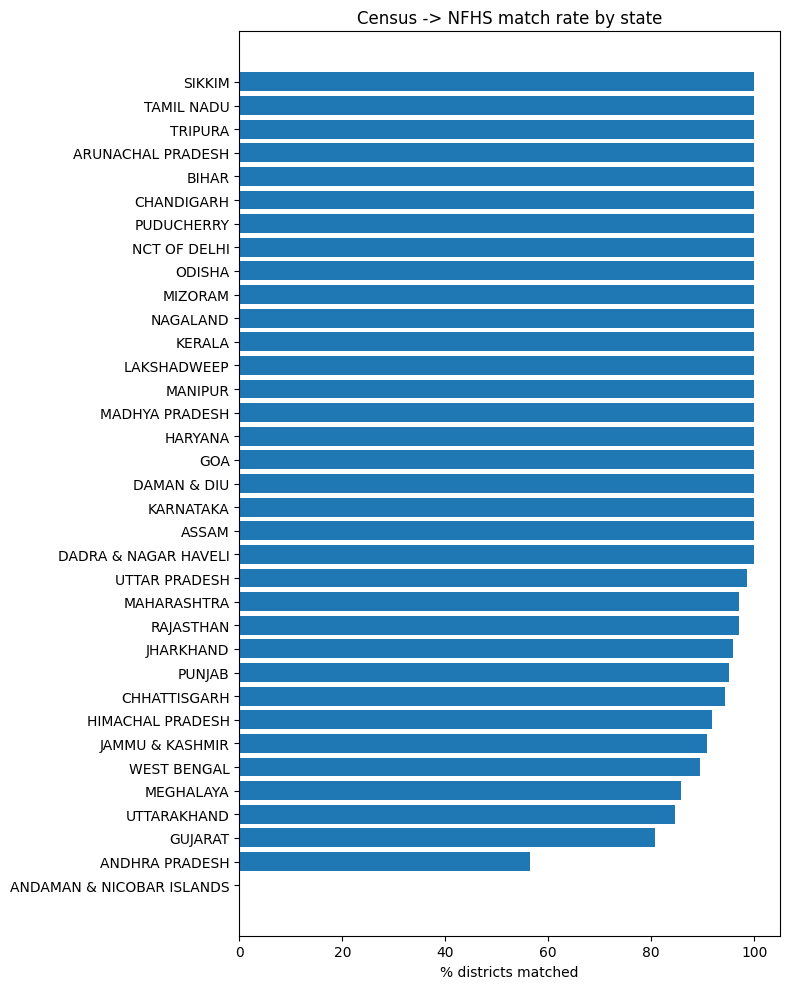

In [89]:
import matplotlib.pyplot as plt

per_state = merged.groupby('State name').agg(
    total=('dkey', 'count'),
    matched=('district_key_nfhs', 'count')   # NaN when a Census district found no NFHS match
).reset_index()
per_state['match_pct'] = (per_state['matched'] / per_state['total'] * 100).round(1)
per_state = per_state.sort_values('match_pct')

plt.figure(figsize=(8, 10))
plt.barh(per_state['State name'], per_state['match_pct'])
plt.xlabel('% districts matched')
plt.title('Census -> NFHS match rate by state')
plt.tight_layout()
plt.show()

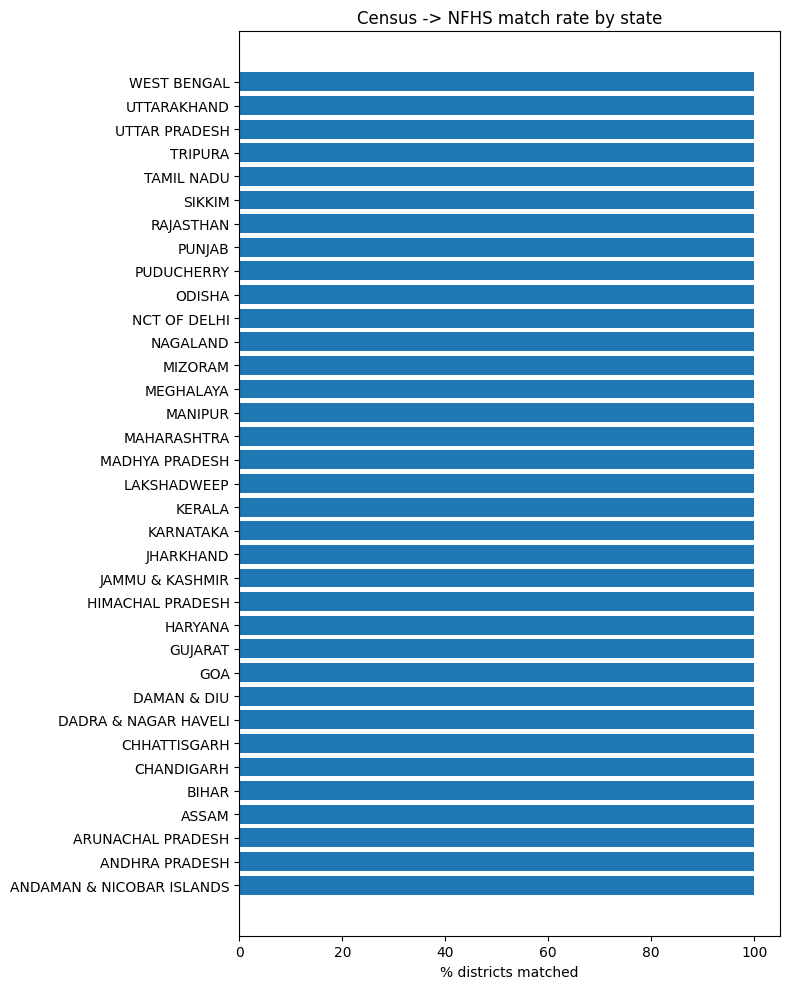

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
per_state = merged.groupby('State name').agg(total=('dkey','count'), matched=('District name','count')).reset_index()
per_state['match_pct'] = (per_state['matched'] / per_state['total'] * 100).round(1)
per_state = per_state.sort_values('match_pct')

plt.figure(figsize=(8,10))
plt.barh(per_state['State name'], per_state['match_pct'])
plt.xlabel('% districts matched')
plt.title('Census -> NFHS match rate by state')
plt.tight_layout()
plt.show()

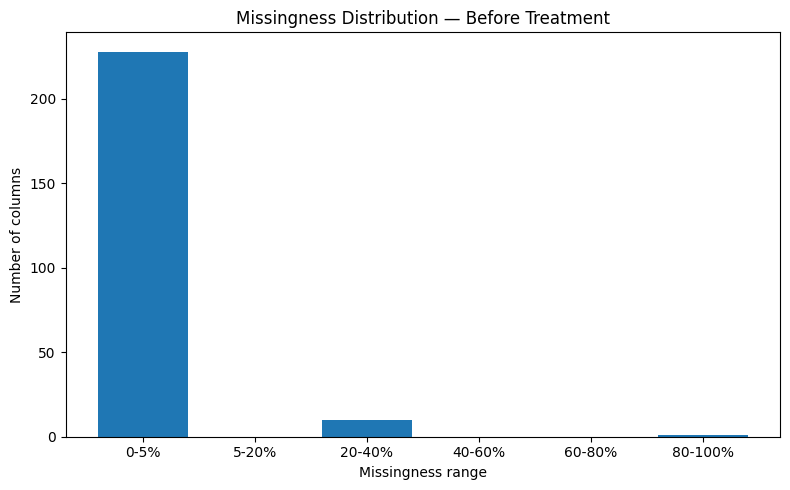

In [91]:
missing_pct = merged.isna().mean() * 100

bins = [0, 5, 20, 40, 60, 80, 100]
labels = ['0-5%', '5-20%', '20-40%', '40-60%', '60-80%', '80-100%']
band_counts = pd.cut(missing_pct, bins=bins, labels=labels, include_lowest=True).value_counts().reindex(labels)

plt.figure(figsize=(8,5))
plt.bar(band_counts.index, band_counts.values)

plt.xlabel('Missingness range')
plt.ylabel('Number of columns')
plt.title('Missingness Distribution — Before Treatment')

plt.tight_layout()
plt.show()

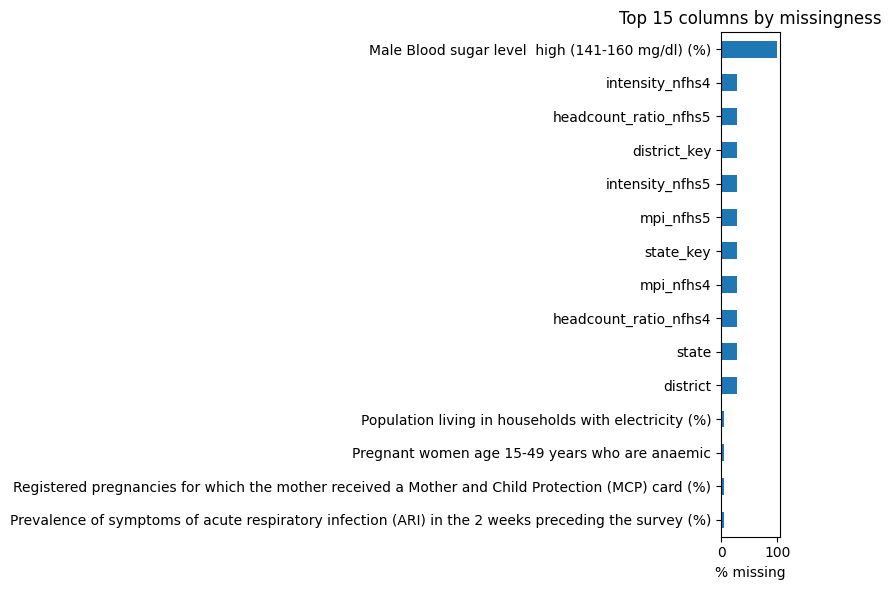

In [92]:
missing_pct.sort_values(ascending=False).head(15).plot.barh(figsize=(8,6))
plt.xlabel('% missing')
plt.title('Top 15 columns by missingness')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [93]:
merged = merged.drop(columns=['Male Blood sugar level  high (141-160 mg/dl) (%)'])

In [94]:
merged['mpi_available'] = merged['mpi_nfhs5'].notna().astype(int)

In [95]:
merged = merged.drop(
    columns=['state'],
    errors='ignore'
)

In [96]:
numeric_cols = merged.select_dtypes(
    include='number'
).columns.tolist()

numeric_cols.remove('is_aspirational')

In [97]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

merged[numeric_cols] = imputer.fit_transform(
    merged[numeric_cols]
)

In [98]:
print(
    "Missing feature values:",
    merged[numeric_cols].isna().sum().sum()
)

print(
    "Missing target values:",
    merged['is_aspirational'].isna().sum()
)

Missing feature values: 0
Missing target values: 0


In [99]:
print(merged.columns.tolist())

['District code', 'State name', 'District name', 'Population', 'Male', 'Female', 'Literate', 'Male_Literate', 'Female_Literate', 'SC', 'Male_SC', 'Female_SC', 'ST', 'Male_ST', 'Female_ST', 'Workers', 'Male_Workers', 'Female_Workers', 'Main_Workers', 'Marginal_Workers', 'Non_Workers', 'Cultivator_Workers', 'Agricultural_Workers', 'Household_Workers', 'Other_Workers', 'Hindus', 'Muslims', 'Christians', 'Sikhs', 'Buddhists', 'Jains', 'Others_Religions', 'Religion_Not_Stated', 'LPG_or_PNG_Households', 'Housholds_with_Electric_Lighting', 'Households_with_Internet', 'Households_with_Computer', 'Rural_Households', 'Urban_Households', 'Households', 'Below_Primary_Education', 'Primary_Education', 'Middle_Education', 'Secondary_Education', 'Higher_Education', 'Graduate_Education', 'Other_Education', 'Literate_Education', 'Illiterate_Education', 'Total_Education', 'Age_Group_0_29', 'Age_Group_30_49', 'Age_Group_50', 'Age not stated', 'Households_with_Bicycle', 'Households_with_Car_Jeep_Van', 'Hou

In [100]:
merged = merged.rename(columns={'Housholds_with_Electric_Lighting': 'Households_with_Electric_Lighting'})

In [101]:
pop_count_cols = [
    'Male','Female','Literate','Male_Literate','Female_Literate','SC','Male_SC','Female_SC',
    'ST','Male_ST','Female_ST','Workers','Male_Workers','Female_Workers','Main_Workers',
    'Marginal_Workers','Non_Workers','Cultivator_Workers','Agricultural_Workers',
    'Household_Workers','Other_Workers','Hindus','Muslims','Christians','Sikhs','Buddhists',
    'Jains','Others_Religions','Religion_Not_Stated','Below_Primary_Education','Primary_Education',
    'Middle_Education','Secondary_Education','Higher_Education','Graduate_Education',
    'Other_Education','Literate_Education','Illiterate_Education','Age_Group_0_29',
    'Age_Group_30_49','Age_Group_50',
]
household_count_cols = [c for c in merged.columns if 'Household' in c and c not in ('Households', 'Household_Workers')]
power_parity_cols = [c for c in merged.columns if c.startswith('Power_Parity_')]

rate_frames = []
for col in pop_count_cols:
    if col in merged.columns:
        rate_frames.append(pd.Series(merged[col] / merged['Population'] * 100, name=col + '_rate'))
for col in household_count_cols + power_parity_cols:
    if col in merged.columns:
        rate_frames.append(pd.Series(merged[col] / merged['Households'] * 100, name=col + '_rate'))
merged['sex_ratio'] = merged['Female'] / merged['Male'] * 1000

merged = pd.concat([merged] + rate_frames, axis=1)
merged = merged.drop(columns=[c for c in pop_count_cols + household_count_cols + power_parity_cols if c in merged.columns])
merged = merged.drop(columns=['Total_Education','Total_Power_Parity'], errors='ignore')

In [102]:
print(merged.columns.tolist())

['District code', 'State name', 'District name', 'Population', 'Households', 'Age not stated', 'district_key_census', 'state_key_census', 'dkey', 'state_key_nfhs', 'district_key_nfhs', 'All women age 15-19 years who are anaemic (%)', 'All women age 15-49 years who are anaemic (%)', 'Any method (%)', 'Any modern method (%)', 'Average out-of-pocket expenditure per delivery in a public health facility (Rs)', 'Births attended by skilled health personnel (%)', 'Births delivered by caesarean section (%)', 'Births in a private health facility that were delivered by caesarean section (%)', 'Births in a public health facility that were delivered by caesarean section (%)', 'Births in the 5 years preceding the survey that are third or higher order (%)', 'Breastfeeding children age 6-23 months receiving an adequate diet (%)', "Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall (%)", 'Children age 12-23 months fully vaccinated based on in

In [103]:
print(
    merged[
        [
            'Population',
            'Literate_rate',
            'Female_rate',
            'SC_rate',
            'ST_rate',
            'Workers_rate',
            'sex_ratio'
        ]
    ].head()
)

   Population  Literate_rate  Female_rate   SC_rate    ST_rate  Workers_rate  \
0    870354.0      50.514388    45.517571  0.120411   8.083148     26.318487   
1    753745.0      44.530843    47.191557  0.048823   3.172426     28.506458   
2    133487.0      70.246541    40.839932  0.365579  71.809989     56.244428   
3    140802.0      61.246289    44.755756  0.012784  86.885129     36.841096   
4    476835.0      54.887749    47.172712  0.116602  36.931224     33.846718   

    sex_ratio  
0  835.454143  
1  893.636585  
2  690.329361  
3  810.143344  
4  892.961068  


In [104]:
import pandas as pd

numeric_cols = merged.select_dtypes(include='number').columns

outlier_summary = []

for col in numeric_cols:
    Q1 = merged[col].quantile(0.25)
    Q3 = merged[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((merged[col] < lower) | (merged[col] > upper)).sum()

    outlier_summary.append({
        'Feature': col,
        'Outliers': outliers,
        'Outlier_%': (outliers / len(merged)) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary = outlier_summary.sort_values(
    'Outliers',
    ascending=False
)

print(outlier_summary.head(30))

                                               Feature  Outliers  Outlier_%
140                              Others_Religions_rate       126   19.68750
136                                    Christians_rate       111   17.34375
30   Children born at home who were taken to a heal...       109   17.03125
137                                         Sikhs_rate       109   17.03125
95   Women age 15 years and above who consume alcoh...       104   16.25000
110                                    is_aspirational       103   16.09375
186  Main_source_of_drinking_water_Spring_Household...       101   15.78125
138                                     Buddhists_rate       101   15.78125
177  Type_of_fuel_used_for_cooking_Any_other_Househ...       100   15.62500
216                   Power_Parity_Rs_45000_90000_rate        94   14.68750
123                                     Female_ST_rate        86   13.43750
218                  Power_Parity_Rs_45000_150000_rate        85   13.28125
121         

In [105]:
print(merged.shape)                          # expect (640, ~234)
print(merged['is_aspirational'].sum())        # expect 103
print('headcount_ratio_nfhs4' in merged.columns and merged['headcount_ratio_nfhs4'].dtype)  # expect float64

(640, 237)
103
float64


In [106]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1) Sanity check: is `merged` in its final prepared state? (expect: True True 103)
print('Literate_rate' in merged.columns,
      'is_aspirational' in merged.columns,
      merged['is_aspirational'].sum() if 'is_aspirational' in merged.columns else None)

# 2) Rebuild the objects the later cells need
id_like = ['District code','District name','State name','District','State','dkey','district_key',
           'district_key_census','district_key_nfhs','state_key','state_key_census','state_key_nfhs',
           'district','state','district_key_mpi','state_key_mpi',
           # columns created later in the notebook, which must never become features
           'is_aspirational','cluster_kmeans','cluster_hier','risk_score','flagged']

feature_cols = [c for c in merged.select_dtypes('number').columns if c not in id_like]
X = merged[feature_cols]

corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.9)]
X_pruned = X.drop(columns=to_drop)

X_pruned_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X_pruned),
    columns=X_pruned.columns,
    index=X_pruned.index
)

clustering_features = [
    'headcount_ratio_nfhs4', 'intensity_nfhs4', 'intensity_nfhs5', 'mpi_available',
    'Literate_rate', 'Workers_rate', 'Households_with_Electric_Lighting_rate',
    'Having_bathing_facility_Total_Households_rate',
    'Location_of_drinking_water_source_Within_the_premises_Households_rate',
    'sex_ratio', 'ST_rate', 'SC_rate',
]
X_cluster = merged[clustering_features]
X_cluster_scaled = StandardScaler().fit_transform(X_cluster)

print(X_pruned.shape, X_pruned_scaled.shape, X_cluster_scaled.shape)   # expect (640, 168) (640, 168) (640, 12)
print('NaNs in X_pruned:', int(X_pruned.isna().sum().sum()))             # expect 0

True True 103
(640, 168) (640, 168) (640, 12)
NaNs in X_pruned: 0


In [107]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

X_pruned_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X_pruned),
    columns=X_pruned.columns,
    index=X_pruned.index
)
print(X_pruned_scaled.shape)

for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_pruned_scaled)
    print(k, round(silhouette_score(X_pruned_scaled, labels), 3))

(640, 168)
2 0.137
3 0.145
4 0.094
5 0.086
6 0.092
7 0.082


In [108]:
import numpy as np
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_pruned_scaled)

explained_variance = pca.explained_variance_ratio_

print("\nExplained variance by each component:")
print(explained_variance)

print("\nCumulative explained variance:")
print(np.cumsum(explained_variance))

pca_95 = PCA(n_components=0.95)
X_pca_95 = pca_95.fit_transform(X_pruned_scaled)

print("\nPCA results")
print("----------------------------")
print("Original features:", X_pruned.shape[1])
print("PCA components for 95% variance:", X_pca_95.shape[1])
print("Variance retained:", round(pca_95.explained_variance_ratio_.sum() * 100, 2), "%")

loadings = pd.DataFrame(
    pca.components_.T,
    index=X_pruned.columns,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)]
)

print("\nPCA Loadings:")
print(loadings.iloc[:, :5].sort_values(by='PC1', key=abs, ascending=False).head(20))


Explained variance by each component:
[2.02403127e-01 8.75148775e-02 7.40722332e-02 4.57000872e-02
 3.67589917e-02 2.96218367e-02 2.69015952e-02 2.52392291e-02
 2.27005970e-02 2.02522642e-02 1.86092869e-02 1.71040092e-02
 1.58920343e-02 1.53749524e-02 1.51823588e-02 1.27133237e-02
 1.19075829e-02 1.15159335e-02 1.06087884e-02 1.04197174e-02
 9.66690347e-03 9.24863346e-03 9.00069393e-03 8.69074334e-03
 8.02711378e-03 7.84775869e-03 7.31247972e-03 6.85440518e-03
 6.73741756e-03 6.54976424e-03 6.29204435e-03 6.03390998e-03
 5.57822251e-03 5.54860145e-03 5.43866584e-03 5.22560227e-03
 5.10122929e-03 4.97734546e-03 4.76993813e-03 4.59840955e-03
 4.57017842e-03 4.35138117e-03 4.23129134e-03 4.11947164e-03
 4.02307809e-03 3.88552319e-03 3.72291254e-03 3.66875912e-03
 3.59009158e-03 3.54057626e-03 3.40746401e-03 3.31907807e-03
 3.20012142e-03 3.10061960e-03 3.00590957e-03 2.88890045e-03
 2.84924680e-03 2.80559064e-03 2.73436138e-03 2.58131427e-03
 2.51054680e-03 2.49001147e-03 2.42514736e-03 

In [109]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_pruned)


pca = PCA()

X_pca = pca.fit_transform(X_scaled)


explained_variance = pca.explained_variance_ratio_

print("\nExplained variance by each component:")
print(explained_variance)

print("\nCumulative explained variance:")
print(np.cumsum(explained_variance))



pca_95 = PCA(n_components=0.95)

X_pca_95 = pca_95.fit_transform(X_scaled)

print("\nPCA results")
print("----------------------------")
print("Original features:", X_pruned.shape[1])
print("PCA components for 95% variance:", X_pca_95.shape[1])
print(
    "Variance retained:",
    round(pca_95.explained_variance_ratio_.sum() * 100, 2),
    "%"
)



loadings = pd.DataFrame(
    pca.components_.T,
    index=X_pruned.columns,
    columns=[
        f"PC{i+1}"
        for i in range(pca.n_components_)
    ]
)

print("\nPCA Loadings:")
print(loadings.iloc[:, :5].sort_values(
    by='PC1',
    key=abs,
    ascending=False
).head(20))


Explained variance by each component:
[2.02403127e-01 8.75148775e-02 7.40722332e-02 4.57000872e-02
 3.67589917e-02 2.96218367e-02 2.69015952e-02 2.52392291e-02
 2.27005970e-02 2.02522642e-02 1.86092869e-02 1.71040092e-02
 1.58920343e-02 1.53749524e-02 1.51823588e-02 1.27133237e-02
 1.19075829e-02 1.15159335e-02 1.06087884e-02 1.04197174e-02
 9.66690347e-03 9.24863346e-03 9.00069393e-03 8.69074334e-03
 8.02711378e-03 7.84775869e-03 7.31247972e-03 6.85440518e-03
 6.73741756e-03 6.54976424e-03 6.29204435e-03 6.03390998e-03
 5.57822251e-03 5.54860145e-03 5.43866584e-03 5.22560227e-03
 5.10122929e-03 4.97734546e-03 4.76993813e-03 4.59840955e-03
 4.57017842e-03 4.35138117e-03 4.23129134e-03 4.11947164e-03
 4.02307809e-03 3.88552319e-03 3.72291254e-03 3.66875912e-03
 3.59009158e-03 3.54057626e-03 3.40746401e-03 3.31907807e-03
 3.20012142e-03 3.10061960e-03 3.00590957e-03 2.88890045e-03
 2.84924680e-03 2.80559064e-03 2.73436138e-03 2.58131427e-03
 2.51054680e-03 2.49001147e-03 2.42514736e-03 

In [110]:
clustering_features = [
    'headcount_ratio_nfhs4',
    'intensity_nfhs4',
    'intensity_nfhs5',
    'mpi_available',
    'Literate_rate',
    'Workers_rate',
    'Households_with_Electric_Lighting_rate',
    'Having_bathing_facility_Total_Households_rate',
    'Location_of_drinking_water_source_Within_the_premises_Households_rate',
    'sex_ratio',
    'ST_rate',
    'SC_rate'
]

In [111]:
X_cluster = merged[clustering_features].copy()

print("\nFinal clustering dataset:")
print("Number of features:", X_cluster.shape[1])
print("Features:")
print(X_cluster.columns.tolist())

print("\nShape:", X_cluster.shape)


Final clustering dataset:
Number of features: 12
Features:
['headcount_ratio_nfhs4', 'intensity_nfhs4', 'intensity_nfhs5', 'mpi_available', 'Literate_rate', 'Workers_rate', 'Households_with_Electric_Lighting_rate', 'Having_bathing_facility_Total_Households_rate', 'Location_of_drinking_water_source_Within_the_premises_Households_rate', 'sex_ratio', 'ST_rate', 'SC_rate']

Shape: (640, 12)


In [112]:
from sklearn.preprocessing import StandardScaler

scaler_final = StandardScaler()

X_cluster_scaled = scaler_final.fit_transform(X_cluster)

print(X_cluster_scaled.shape)

(640, 12)


In [113]:
from sklearn.metrics import adjusted_rand_score

merged = merged.copy()   # defragments the dataframe, removes the PerformanceWarning

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
merged['cluster_kmeans'] = kmeans.fit_predict(X_cluster_scaled)   # the 12 curated features

hier = AgglomerativeClustering(n_clusters=k)
merged['cluster_hier'] = hier.fit_predict(X_cluster_scaled)

print('ARI:', round(adjusted_rand_score(merged['cluster_kmeans'], merged['cluster_hier']), 3))
print(merged['cluster_kmeans'].value_counts().sort_index())

ARI: 0.63
cluster_kmeans
0    193
1    163
2    284
Name: count, dtype: int64


In [114]:
import pandas as pd, numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

y = merged['is_aspirational']

# Lasso (L1) selection
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.1,
                           class_weight='balanced', random_state=42)
lasso.fit(X_pruned_scaled, y)
lasso_selected = set(X_pruned.columns[np.abs(lasso.coef_[0]) > 0])

# Random Forest importance selection (top 40)
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf.fit(X_pruned_scaled, y)
rf_importance = pd.Series(rf.feature_importances_, index=X_pruned.columns).sort_values(ascending=False)
rf_selected = set(rf_importance.head(40).index)

# Consensus: features both methods agree on
consensus = sorted(lasso_selected & rf_selected)
print(f'Lasso kept {len(lasso_selected)} | RF top 40 | consensus {len(consensus)}')
for f in consensus:
    print(' -', f)

Lasso kept 39 | RF top 40 | consensus 15
 - Agricultural_Workers_rate
 - Children under 5 years who are stunted (height for age) (%)
 - Female population age 6 years and above who ever attended school (%)
 - Higher_Education_rate
 - Home births that were conducted by skilled health personnel (%)
 - Literate_Education_rate
 - Literate_rate
 - Main_source_of_drinking_water_Tapwater_Households_rate
 - Main_source_of_drinking_water_Un_covered_well_Households_rate
 - Population
 - Population below age 15 years (%)
 - Population living in households that use an improved sanitation facility (%)
 - Sikhs_rate
 - Women whose Body Mass Index (BMI) is below normal (BMI <18)
 - headcount_ratio_nfhs4


In [115]:
# STAGE 3: Domain review of the Lasso + RF consensus list

# Drop features that look like geography or size proxies
# rather than actual development indicators.
drop_after_review = ['Population', 'Sikhs_rate']

final_features = [f for f in consensus if f not in drop_after_review]

print(f'{len(consensus)} consensus features -> {len(final_features)} after review')

for f in final_features:
    print(' -', f)

15 consensus features -> 13 after review
 - Agricultural_Workers_rate
 - Children under 5 years who are stunted (height for age) (%)
 - Female population age 6 years and above who ever attended school (%)
 - Higher_Education_rate
 - Home births that were conducted by skilled health personnel (%)
 - Literate_Education_rate
 - Literate_rate
 - Main_source_of_drinking_water_Tapwater_Households_rate
 - Main_source_of_drinking_water_Un_covered_well_Households_rate
 - Population below age 15 years (%)
 - Population living in households that use an improved sanitation facility (%)
 - Women whose Body Mass Index (BMI) is below normal (BMI <18)
 - headcount_ratio_nfhs4


In [116]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(merged['cluster_kmeans'], merged['is_aspirational'])
print(ct)

base_rate = merged['is_aspirational'].mean()
summary = pd.DataFrame({
    'districts': ct.sum(axis=1),
    'aspirational': ct[1],
    'aspirational_%': (ct[1] / ct.sum(axis=1) * 100).round(1),
    'enrichment_x': ((ct[1] / ct.sum(axis=1)) / base_rate).round(2),
})
print()
print(summary)

chi2, p, _, _ = chi2_contingency(ct.values)
print(f'\nchi-square p-value: {p:.2e}')

print()
print(merged.groupby('cluster_kmeans')[clustering_features].mean().round(1).T)

is_aspirational    0   1
cluster_kmeans          
0                147  46
1                117  46
2                273  11

                districts  aspirational  aspirational_%  enrichment_x
cluster_kmeans                                                       
0                     193            46            23.8          1.48
1                     163            46            28.2          1.75
2                     284            11             3.9          0.24

chi-square p-value: 2.92e-13

cluster_kmeans                                          0      1      2
headcount_ratio_nfhs4                                34.0   28.0   13.4
intensity_nfhs4                                      46.5   45.3   42.3
intensity_nfhs5                                      43.8   43.0   40.5
mpi_available                                         0.8    0.7    0.7
Literate_rate                                        55.9   57.3   69.9
Workers_rate                                         35.5   4

In [117]:
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve
)

y = merged['is_aspirational']
groups = merged['State name']


class InFoldSelect(BaseEstimator, ClassifierMixin):
    """Select features using only the training fold."""

    def __init__(self, final_model=None, drop=()):
        self.final_model = final_model
        self.drop = drop

    def fit(self, X, y):
        Xs = pd.DataFrame(
            StandardScaler().fit_transform(X),
            columns=X.columns,
            index=X.index
        )

        lasso = LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=0.1,
            class_weight='balanced',
            random_state=42
        ).fit(Xs, y)

        rf = RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ).fit(Xs, y)

        l_sel = set(X.columns[np.abs(lasso.coef_[0]) > 0])

        r_sel = set(
            pd.Series(
                rf.feature_importances_,
                index=X.columns
            ).nlargest(40).index
        )

        cols = [
            c for c in X.columns
            if c in (l_sel & r_sel) and c not in self.drop
        ]

        # Fallback if the reviewed consensus is empty
        if not cols:
            cols = [c for c in X.columns if c in r_sel and c not in self.drop]

        if not cols:
            cols = list(X.columns)

        self.cols_ = cols
        self.model_ = clone(self.final_model).fit(X[cols], y)

        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X[self.cols_])


lr_model = lambda: make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.1,
        class_weight='balanced',
        max_iter=3000
    )
)

rf_model = lambda: RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

svm_model = lambda: make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1, class_weight='balanced')
)


experiments = [
    ('all 168 features', X_pruned, {
        'Logistic Regression': lr_model,
        'Random Forest': rf_model,
        'SVM (RBF)': svm_model
    }),

    ('shortlist picked inside each fold', X_pruned, {
        'Logistic Regression': lambda: InFoldSelect(
            lr_model(), drop=tuple(drop_after_review)
        ),
        'Random Forest': lambda: InFoldSelect(
            rf_model(), drop=tuple(drop_after_review)
        )
    }),

    ('shortlist picked on ALL data (optimistic)',
     X_pruned[final_features], {
        'Logistic Regression': lr_model,
        'Random Forest': rf_model
    })
]


cvs = {
    'state-held-out': GroupKFold(n_splits=5),
    'random folds': StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    )
}


def get_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(y_true, scores):
    precision, recall, _ = precision_recall_curve(y_true, scores)

    return {
        'AP': average_precision_score(y_true, scores),
        'AUC': roc_auc_score(y_true, scores),
        'prec@recall50': (
            precision[recall >= 0.50].max()
            if (recall >= 0.50).any() else np.nan
        ),
        'prec@recall75': (
            precision[recall >= 0.75].max()
            if (recall >= 0.75).any() else np.nan
        )
    }


oof_store, rows = {}, []

for fs_name, X_exp, model_dict in experiments:
    for model_name, make_model in model_dict.items():
        for cv_name, splitter in cvs.items():
            scores = np.zeros(len(X_exp))

            for tr, te in splitter.split(X_exp, y, groups):
                model = make_model().fit(
                    X_exp.iloc[tr], y.iloc[tr]
                )
                scores[te] = get_scores(
                    model, X_exp.iloc[te]
                )

            oof_store[(fs_name, model_name, cv_name)] = scores

            rows.append({
                'features': fs_name,
                'model': model_name,
                'cv': cv_name,
                **evaluate(y, scores)
            })


# Simple baseline comparisons
for baseline_name, baseline_scores in {
    'baseline: poverty headcount (NFHS-4 MPI)':
        merged['headcount_ratio_nfhs4'],
    'baseline: low literacy':
        -merged['Literate_rate']
}.items():
    rows.append({
        'features': '-',
        'model': baseline_name,
        'cv': 'n/a',
        **evaluate(y, baseline_scores.values)
    })


results = pd.DataFrame(rows)

print(f'Random-guess AP would be {y.mean():.3f}\n')
print(
    results.round(3)
    .sort_values(['cv', 'AP'], ascending=[False, False])
    .to_string(index=False)
)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/

Random-guess AP would be 0.161

                                 features                                    model             cv    AP   AUC  prec@recall50  prec@recall75
shortlist picked on ALL data (optimistic)                      Logistic Regression state-held-out 0.534 0.813          0.495          0.329
shortlist picked on ALL data (optimistic)                            Random Forest state-held-out 0.458 0.754          0.456          0.253
                         all 168 features                            Random Forest state-held-out 0.403 0.757          0.438          0.293
        shortlist picked inside each fold                      Logistic Regression state-held-out 0.374 0.751          0.405          0.256
        shortlist picked inside each fold                            Random Forest state-held-out 0.369 0.710          0.329          0.225
                         all 168 features                                SVM (RBF) state-held-out 0.360 0.734          0.384    

Using the best honest model: ('all 168 features', 'Random Forest', 'state-held-out') | AP 0.403
 recall target  threshold  recall  precision  districts flagged  % of all districts
          0.50      0.253   0.524      0.435                124                19.4
          0.60      0.213   0.602      0.383                162                25.3
          0.75      0.137   0.757      0.293                266                41.6

Operating point: recall >= 0.6, threshold 0.213, 162 districts flagged


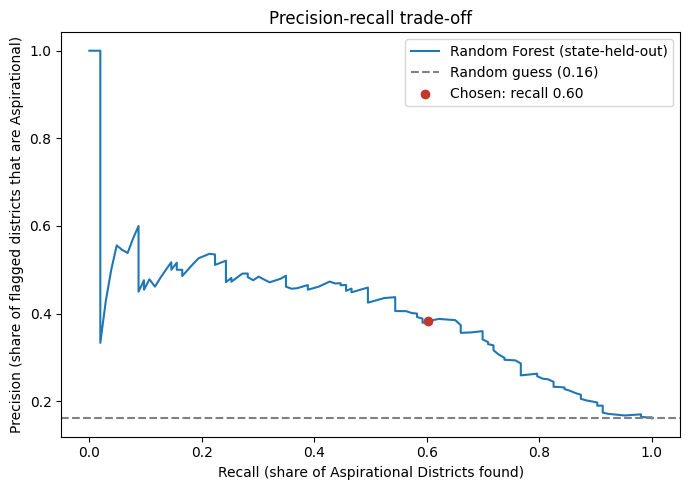

In [118]:
import matplotlib.pyplot as plt

# Pick which out-of-fold scores to use. Every score below comes from a model that never saw that district's state.
honest_sets = ['all 168 features', 'shortlist picked inside each fold']
honest = results[(results['cv'] == 'state-held-out') & (results['features'].isin(honest_sets))]
best = honest.sort_values('AP', ascending=False).iloc[0]
chosen = (best['features'], best['model'], 'state-held-out')
print('Using the best honest model:', chosen, '| AP', round(best['AP'], 3))
scores = oof_store[chosen]
merged['risk_score'] = scores

pr, rc, th = precision_recall_curve(y, scores)

def threshold_for_recall(target):
    i = np.where(rc[:-1] >= target)[0].max()      # highest threshold that still reaches the recall target
    return i, th[i]

rows = []
for target in [0.50, 0.60, 0.75]:
    i, thr = threshold_for_recall(target)
    flagged = scores >= thr
    rows.append({'recall target': target, 'threshold': round(thr, 3),
                 'recall': round(rc[i], 3), 'precision': round(pr[i], 3),
                 'districts flagged': int(flagged.sum()),
                 '% of all districts': round(flagged.mean() * 100, 1)})
print(pd.DataFrame(rows).to_string(index=False))

# Choose the operating point you will report, then flag districts with it
target_recall = 0.60
i_sel, thr_sel = threshold_for_recall(target_recall)
merged['flagged'] = (merged['risk_score'] >= thr_sel).astype(int)
print(f'\nOperating point: recall >= {target_recall}, threshold {thr_sel:.3f}, '
      f'{merged["flagged"].sum()} districts flagged')

plt.figure(figsize=(7, 5))
plt.plot(rc, pr, label=f'{chosen[1]} (state-held-out)')
plt.axhline(y.mean(), color='grey', linestyle='--', label=f'Random guess ({y.mean():.2f})')
plt.scatter([rc[i_sel]], [pr[i_sel]], color='#c0392b', zorder=5, label=f'Chosen: recall {rc[i_sel]:.2f}')
plt.xlabel('Recall (share of Aspirational Districts found)')
plt.ylabel('Precision (share of flagged districts that are Aspirational)')
plt.title('Precision-recall trade-off')
plt.legend()
plt.tight_layout()
plt.savefig('precision_recall.png', dpi=150)
plt.show()

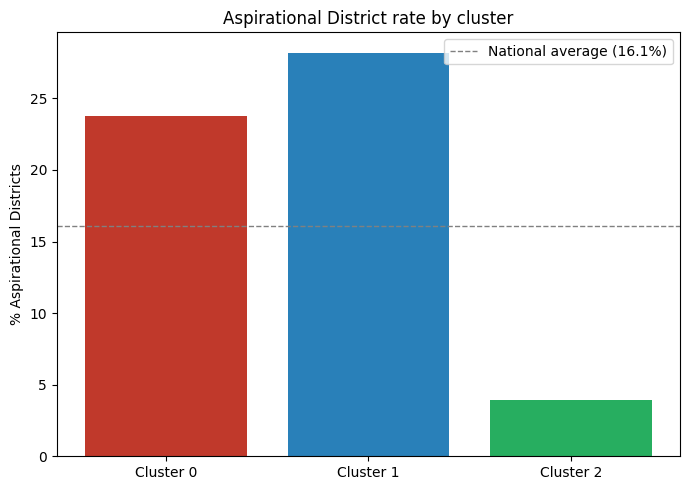

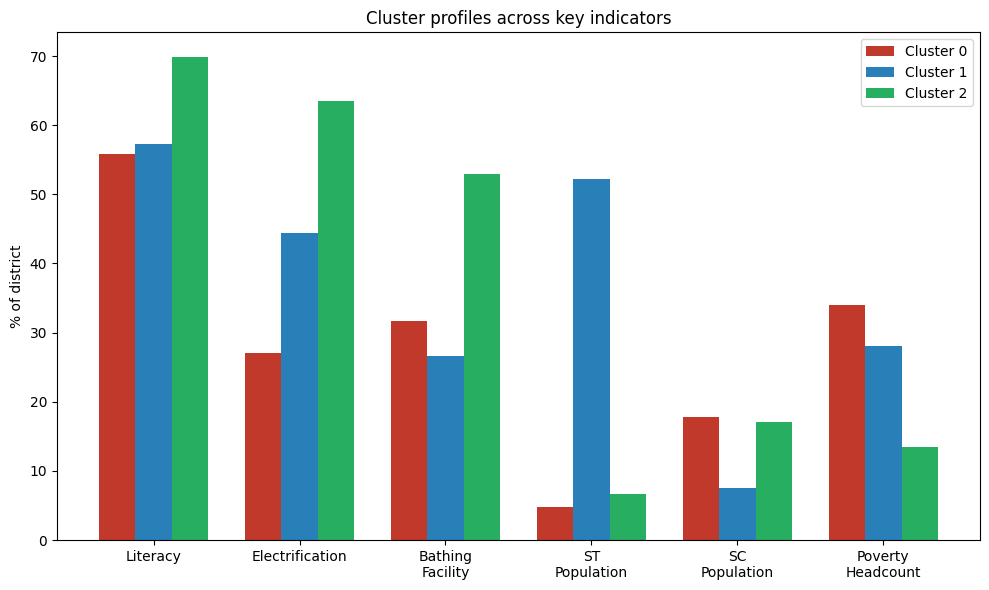

In [119]:
import matplotlib.pyplot as plt
import numpy as np

# Edit these names AFTER reading the profile table printed by the previous cell
cluster_names = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2'}
colors = {0: '#c0392b', 1: '#2980b9', 2: '#27ae60'}

order = sorted(merged['cluster_kmeans'].unique())
asp_rate = (merged.groupby('cluster_kmeans')['is_aspirational'].mean() * 100).round(1)
base_rate = merged['is_aspirational'].mean() * 100

# Chart 1: aspirational rate per cluster
plt.figure(figsize=(7, 5))
plt.bar([cluster_names[c] for c in order], [asp_rate[c] for c in order],
        color=[colors[c] for c in order])
plt.axhline(base_rate, color='grey', linestyle='--', linewidth=1,
            label=f'National average ({base_rate:.1f}%)')
plt.ylabel('% Aspirational Districts')
plt.title('Aspirational District rate by cluster')
plt.legend()
plt.tight_layout()
plt.savefig('cluster_aspirational_rate.png', dpi=150)
plt.show()

# Chart 2: cluster profiles
profile_cols = {
    'Literate_rate': 'Literacy',
    'Households_with_Electric_Lighting_rate': 'Electrification',
    'Having_bathing_facility_Total_Households_rate': 'Bathing\nFacility',
    'ST_rate': 'ST\nPopulation',
    'SC_rate': 'SC\nPopulation',
    'headcount_ratio_nfhs4': 'Poverty\nHeadcount',
}
profile = merged.groupby('cluster_kmeans')[list(profile_cols)].mean()

x = np.arange(len(profile_cols))
width = 0.25
plt.figure(figsize=(10, 6))
for i, c in enumerate(order):
    plt.bar(x + (i - 1) * width, profile.loc[c].values, width,
            label=cluster_names[c], color=colors[c])
plt.xticks(x, list(profile_cols.values()))
plt.ylabel('% of district')
plt.title('Cluster profiles across key indicators')
plt.legend()
plt.tight_layout()
plt.savefig('cluster_profiles.png', dpi=150)
plt.show()

In [120]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, precision_score, recall_score

def honest_cv(seed):
    """Feature selection is redone inside every training fold, so test folds never influence it."""
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    out = {'all': [], 'selected': []}
    for tr, te in cv.split(X_pruned, y):
        sc = StandardScaler().fit(X_pruned.iloc[tr])
        Xtr = pd.DataFrame(sc.transform(X_pruned.iloc[tr]), columns=X_pruned.columns)
        Xte = pd.DataFrame(sc.transform(X_pruned.iloc[te]), columns=X_pruned.columns)
        ytr, yte = y.iloc[tr], y.iloc[te]

        rf_all = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42).fit(Xtr, ytr)
        p = rf_all.predict(Xte)
        out['all'].append((f1_score(yte, p), precision_score(yte, p, zero_division=0), recall_score(yte, p)))

        lasso_f = LogisticRegression(penalty='l1', solver='liblinear', C=0.1,
                                     class_weight='balanced', random_state=42).fit(Xtr, ytr)
        l_sel = set(X_pruned.columns[np.abs(lasso_f.coef_[0]) > 0])
        r_sel = set(pd.Series(rf_all.feature_importances_, index=X_pruned.columns).nlargest(40).index)
        cons = list(l_sel & r_sel) or list(r_sel)

        rf_sel = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42).fit(Xtr[cons], ytr)
        p = rf_sel.predict(Xte[cons])
        out['selected'].append((f1_score(yte, p), precision_score(yte, p, zero_division=0), recall_score(yte, p)))
    return out

rows = []
for seed in [42, 7, 123]:
    res = honest_cv(seed)
    for name in ['all', 'selected']:
        f1, pr, rc = np.mean(res[name], axis=0)
        rows.append({'seed': seed, 'features': name, 'F1': f1, 'precision': pr, 'recall': rc})

report = pd.DataFrame(rows)
print(report.round(3).to_string(index=False))
print()
print(report.groupby('features')[['F1', 'precision', 'recall']].mean().round(3))

 seed features    F1  precision  recall
   42      all 0.394      0.793   0.271
   42 selected 0.350      0.592   0.252
    7      all 0.385      0.742   0.263
    7 selected 0.382      0.686   0.272
  123      all 0.399      0.716   0.291
  123 selected 0.393      0.627   0.300

             F1  precision  recall
features                          
all       0.392      0.750   0.275
selected  0.375      0.635   0.275


In [121]:
cols = ['State name', 'District name', 'risk_score']

print(
    'Highest-scoring districts that are NOT on the '
    'Aspirational list (candidates for review):'
)

print(
    merged[merged['is_aspirational'] == 0]
    .nlargest(15, 'risk_score')[cols]
    .round(3)
    .to_string(index=False)
)


print(
    '\nAspirational districts the model scores lowest '
    '(the ones it misses):'
)

print(
    merged[merged['is_aspirational'] == 1]
    .nsmallest(15, 'risk_score')[cols]
    .round(3)
    .to_string(index=False)
)


print(
    '\nAspirational districts found vs. missed, by state:'
)

by_state = (
    merged[merged['is_aspirational'] == 1]
    .groupby('State name')['flagged']
    .agg(found='sum', total='count')
)

by_state['missed'] = (
    by_state['total'] - by_state['found']
)

print(
    by_state.sort_values(
        'missed', ascending=False
    ).to_string()
)

Highest-scoring districts that are NOT on the Aspirational list (candidates for review):
    State name District name  risk_score
MADHYA PRADESH        Umaria       0.663
MADHYA PRADESH         Sidhi       0.630
MADHYA PRADESH         Panna       0.627
MADHYA PRADESH       Dindori       0.593
     JHARKHAND       Deoghar       0.570
MADHYA PRADESH       Shahdol       0.557
MADHYA PRADESH        Mandla       0.543
MADHYA PRADESH     Alirajpur       0.537
     JHARKHAND       Jamtara       0.523
MADHYA PRADESH        Jhabua       0.523
         BIHAR       Saharsa       0.520
MADHYA PRADESH       Sheopur       0.510
         BIHAR    Kishanganj       0.493
         BIHAR     Madhepura       0.493
MADHYA PRADESH      Shivpuri       0.460

Aspirational districts the model scores lowest (the ones it misses):
      State name       District name  risk_score
     UTTARAKHAND             Hardwar       0.013
       JHARKHAND     Purbi Singhbhum       0.017
          PUNJAB            Firozpur  